# Multi-Fidelity Method Comparison: Forrester Function

Example is based on the 2007 paper "Multi-fidelity optimization via surrogate modelling" by Forrester, Sobester, and Keane.

In [40]:
# Boilerplate for automatic reloading of modules on run and connecting to paths of local code.

%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import torch
import numpy as np

from SurrogateModels import mfsnn, cokriging, mfkans, kriging
import multi_fidelity_functions

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Introduce the example function

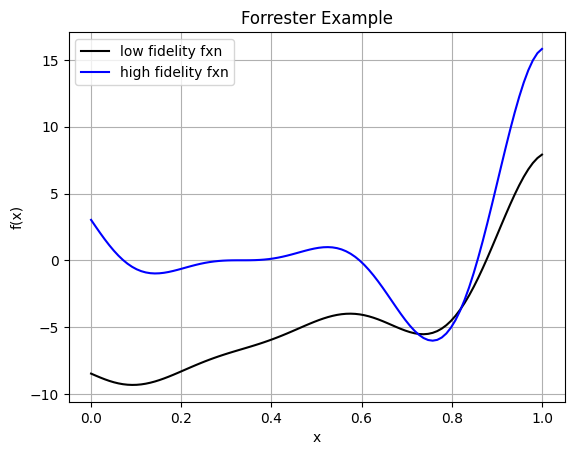

In [3]:
import multi_fidelity_functions
import matplotlib.pyplot as plt

mf_example = multi_fidelity_functions.ForresterExample()
mf_example.plot_functions(name=mf_example.name)
plt.legend()
plt.grid()
plt.show()

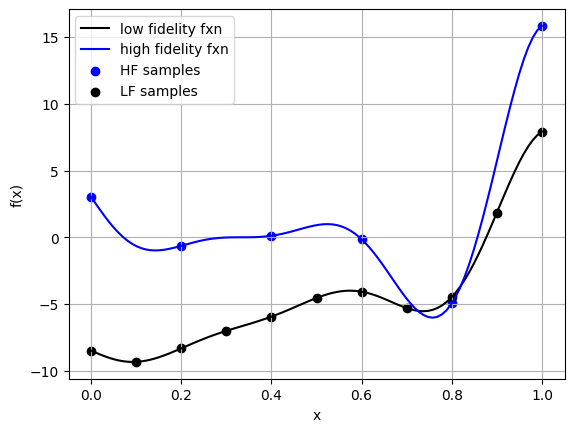

In [33]:
# Define the example function bounds and dimensions here
dim = mf_example.dimensions
xmin = mf_example.bounds[0][0]
xmax = mf_example.bounds[0][1]

n_lf = 11  # number of low fidelity points
n_hf = 6  # number of high fidelity points
n_test = 40  # number of test points

# Generate the analytical functions
hf_fxn = mf_example.high_fidelity
lf_fxn = mf_example.low_fidelity

X_lf = np.linspace(xmin, xmax, n_lf, dtype=np.float32).reshape(-1, 1)
y_lf = lf_fxn(X_lf)

X_hf = np.linspace(xmin, xmax, n_hf, dtype=np.float32).reshape(-1, 1)
y_hf = hf_fxn(X_hf)

X_test = np.linspace(xmin, xmax, n_test, dtype=np.float32).reshape(-1, 1)
y_lf_test = lf_fxn(X_test)
y_hf_test = hf_fxn(X_test)

plot_name = mf_example.name + " Samples"

mf_example.plot_functions(name=plot_name)

plt.figure(plot_name)
plt.title("")
plt.scatter(X_hf, y_hf, color="blue", label="HF samples", marker="o")
plt.scatter(X_lf, y_lf, color="black", label="LF samples", marker="o")
plt.legend()
plt.grid()
plt.show()

## Multi-Fidelity Neural Network Fit

Using the method outlined by Meng and Karniadakis in the 2020 paper 
"A composite neural network that learns from multi-fidelity data: Application to function approximation and inverse PDE problems"
 generate a multi-fidelity function fit using the data defined from the analytical functions.

In [27]:
mfnn_model = mfsnn.MultiFidelityNN(
    X_lf=X_lf,
    y_lf=y_lf,
    X_lf_test=X_test,
    y_lf_test=y_lf_test,
    X_hf=X_hf,
    y_hf=y_hf,
    X_hf_test=X_test,
    y_hf_test=y_hf_test,
    lf_nn_dim=[20, 20, 20],
    hf_nl_nn_dim=[8, 5],
    epochs_lf=100,
    epochs_mf=15000,
    lr_lf=0.001,
    wd_lf=0.000001,
    lr_mf=0.001,
    wd_mf=0.05,
)

Epoch: 0   || Train Error: 2.9274582862854004 || Test Error: 0.7307333946228027

Epoch: 1   || Train Error: 2.509016275405884 || Test Error: 0.6031116247177124

Epoch: 2   || Train Error: 2.1895065307617188 || Test Error: 0.5078176856040955

Epoch: 3   || Train Error: 1.3555573225021362 || Test Error: 0.28689587116241455

Epoch: 4   || Train Error: 0.9847745895385742 || Test Error: 0.2014831006526947

Epoch: 5   || Train Error: 0.7328919768333435 || Test Error: 0.1492641270160675

Epoch: 6   || Train Error: 0.6491426825523376 || Test Error: 0.13385747373104095

Epoch: 7   || Train Error: 0.6062268018722534 || Test Error: 0.12669737637043

Epoch: 8   || Train Error: 0.5789579749107361 || Test Error: 0.12253771722316742

Epoch: 9   || Train Error: 0.5519017577171326 || Test Error: 0.1187695637345314

Epoch: 10   || Train Error: 0.5313980579376221 || Test Error: 0.11617438495159149

Epoch: 11   || Train Error: 0.5049076080322266 || Test Error: 0.1130509003996849

Epoch: 12   || Train Erro

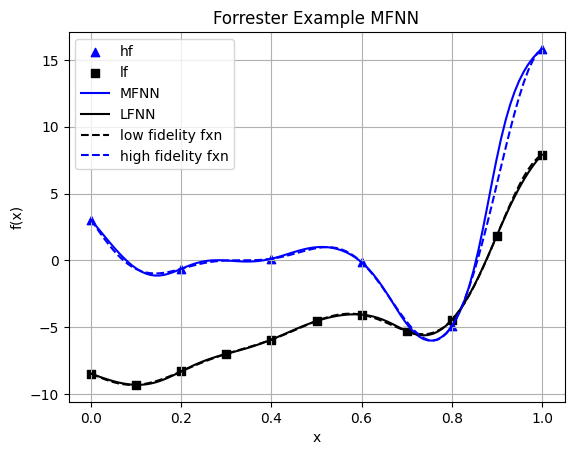

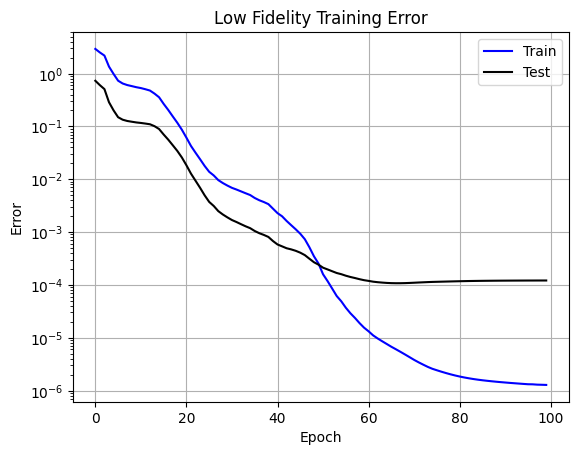

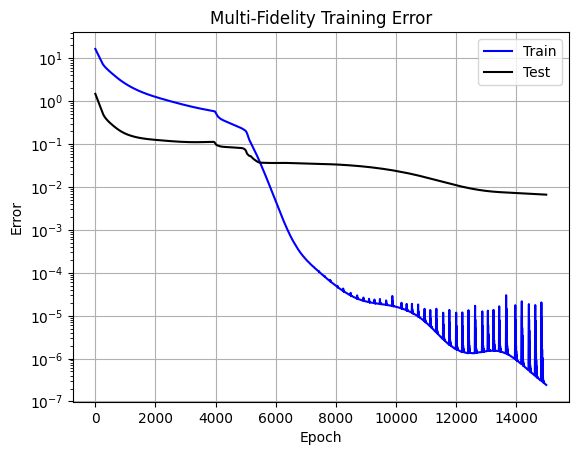

In [28]:
# Plot the results
plot_name = mf_example.name + " MFNN"

ax = mfnn_model.plot_data(plot_name)
ax = mfnn_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="blue",
    label="MFNN",
    linestyle="solid",
    ax=ax,
)
ax = mfnn_model.low_fidelity_nn.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="black",
    label="LFNN",
    linestyle="solid",
    ax=ax,
)
ax = mf_example.plot_functions(name=plot_name, linestyle="dashed", ax=ax)
plt.legend()
plt.grid()
plt.show()

# Plot the model error
mfnn_model.low_fidelity_nn.plot_training_error("Low Fidelity Training Error")
plt.yscale("log")
plt.grid()
plt.show()
mfnn_model.high_fidelity_nn.plot_training_error("Multi-Fidelity Training Error")
plt.yscale("log")
plt.grid()
plt.show()

## Co-Kriging Function Fit

Utilizes the Co-Kriging function fit outlined in the Forrester 2007 paper.

In [41]:
cokriging_model = cokriging.CoKriging(X_lf, y_lf, X_hf, y_hf)
kriging_model = kriging.Kriging(X_hf, y_hf)

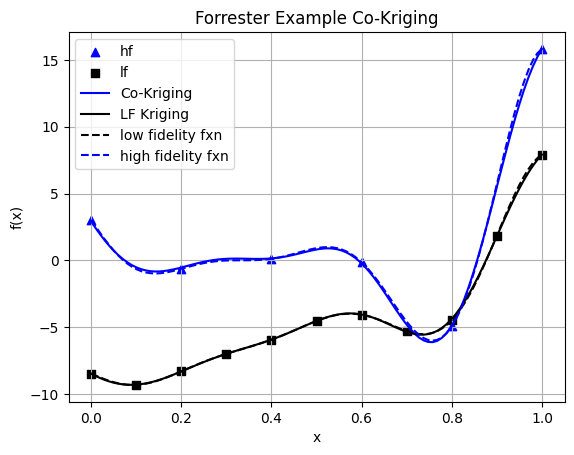

In [8]:
# Plot the results
plot_name = mf_example.name + " Co-Kriging"

ax = cokriging_model.plot_data(plot_name)
ax = cokriging_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="blue",
    label="Co-Kriging",
    linestyle="solid",
    ax=ax,
)
ax = cokriging_model.kriging_lf.plot_model(
    mf_example.bounds,
    name=plot_name,
    label="LF Kriging",
    color="black",
    linestyle="solid",
    ax=ax,
)
ax = mf_example.plot_functions(name=plot_name, linestyle="dashed", ax=ax)
plt.legend()
plt.grid()
plt.show()

### MFKAN Model
Sets up a MFKAN model for a 1D dataset

In [9]:
# MFKAN Model for forrester mf example
mfkan_model = mfkans.MFKANModel(
    x_lf=X_lf,
    y_lf=y_lf,
    x_lf_test=X_test,
    y_lf_test=y_lf_test,
    x_hf=X_hf,
    y_hf=y_hf,
    x_hf_test=X_test,
    y_hf_test=y_hf_test,
    spline_order_lf=3,
    spline_order_mf=3,
    width_lf=[1, 1],
    width_mf=[2, 1],
    grid_lf=[10],
    grid_mf=[2],
    opt_lf="LBFGS",
    opt_mf="LBFGS",
    n_iter_lf=100,
    n_iter_mf=100,
)

checkpoint directory created: ./model
saving model version 0.0


| train_loss: 5.43e-07 | test_loss: 8.88e-02 | reg: 1.22e+01 | : 100%|█| 100/100 [00:04<00:00, 20.76


saving model version 0.1
checkpoint directory created: ./model
saving model version 0.0


| train_loss: 9.74e-07 | test_loss: 2.87e-01 | reg: 1.25e+01 | : 100%|█| 100/100 [00:04<00:00, 20.47

saving model version 0.1


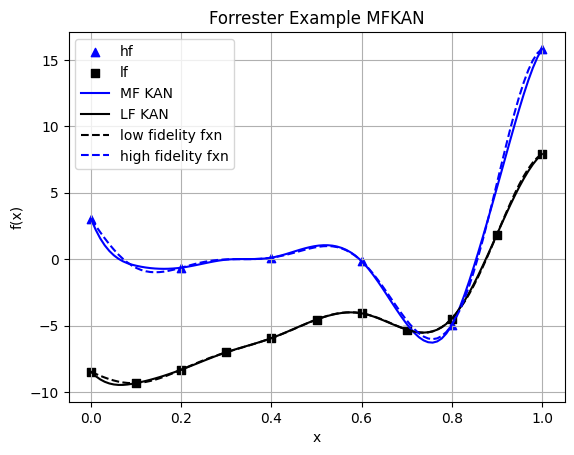

In [10]:
# Plot the results
plot_name = mf_example.name + " MFKAN"

ax = mfkan_model.plot_data(plot_name)
ax = mfkan_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="blue",
    label="MF KAN",
    linestyle="solid",
    ax=ax,
)
ax = mfkan_model.lf_kan_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    label="LF KAN",
    color="black",
    linestyle="solid",
    ax=ax,
)
ax = mf_example.plot_functions(name=plot_name, linestyle="dashed", ax=ax)
plt.legend()
plt.grid()
plt.show()

### Method Comparison

Compare the three different methods for their ability to fit the high fidelity function.

TypeError: only length-1 arrays can be converted to Python scalars

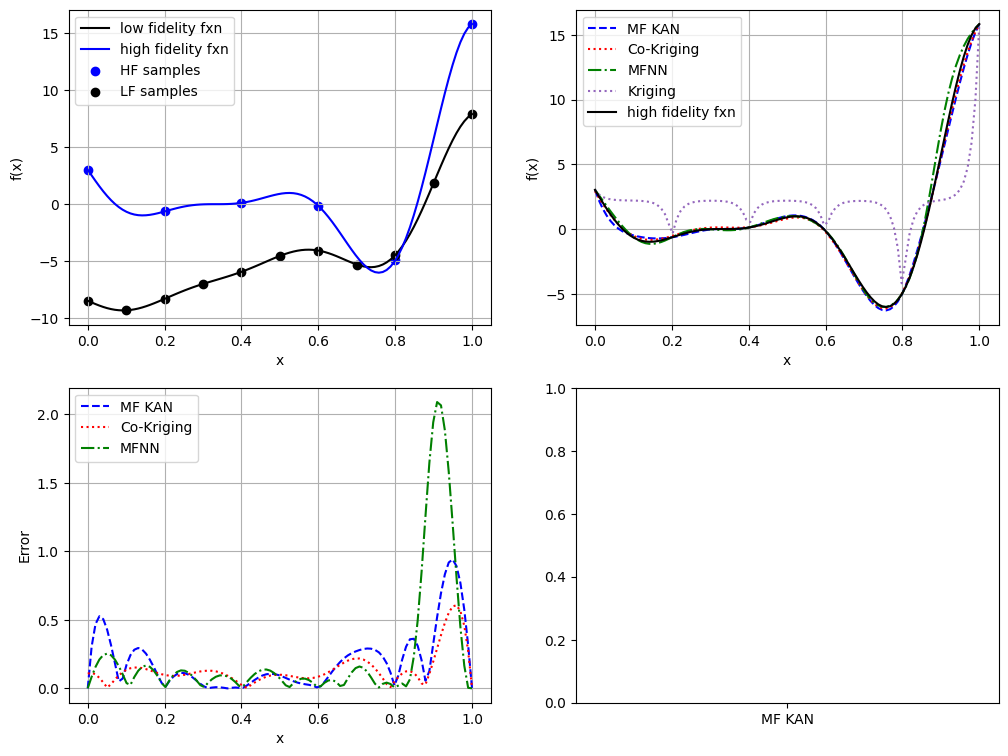

In [ ]:
# Set figure size for plots
fig = plt.figure(figsize=(12,9))

# Plot the models and sample data
ax = fig.add_subplot(221)

plot_name = ""

ax = mf_example.plot_functions(name=plot_name, ax=ax)

ax.set_title(plot_name)
ax.scatter(X_hf, y_hf, color="blue", label="HF samples", marker="o")
ax.scatter(X_lf, y_lf, color="black", label="LF samples", marker="o")
ax.grid()
ax.legend()

plot_name = ""

# Plot the model fits
ax = fig.add_subplot(222)

ax = mfkan_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="blue",
    label="MF KAN",
    linestyle="dashed",
    ax=ax
)
ax = cokriging_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="red",
    label="Co-Kriging",
    linestyle="dotted",
    ax=ax,
)
ax = mfnn_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="green",
    label="MFNN",
    linestyle="dashdot",
    ax=ax,
)
ax = kriging_model.plot_model(
    mf_example.bounds,
    name=plot_name,
    color="tab:purple",
    label="Kriging",
    linestyle="dotted",
    ax=ax,
)
ax = mf_example.plot_high_fidelity(
    name=plot_name, linestyle="solid", color="black", ax=ax
)
ax.grid()
ax.legend()

# Plot the error comparison
ax = fig.add_subplot(223)
plot_name = ""

ax = mfkan_model.plot_rms_error(
    mf_example.bounds,
    mf_example.high_fidelity,
    name=plot_name,
    color="blue",
    label="MF KAN",
    linestyle="dashed",
    ax=ax
)
ax = cokriging_model.plot_rms_error(
    mf_example.bounds,
    mf_example.high_fidelity,
    name=plot_name,
    color="red",
    label="Co-Kriging",
    linestyle="dotted",
    ax=ax,
)
ax = mfnn_model.plot_rms_error(
    mf_example.bounds,
    mf_example.high_fidelity,
    name=plot_name,
    color="green",
    label="MFNN",
    linestyle="dashdot",
    ax=ax,
)
ax.grid()
ax.legend()


# Plot the error comparison
ax = fig.add_subplot(224)
plot_name = ""
names = ["MF KAN", "Co-Kriging", "MFNN", "Kriging"]
print(mfkan_model.bounded_model_error(mf_example.bounds, mf_example.high_fidelity))
error = [mfkan_model.bounded_model_error(mf_example.bounds, mf_example.high_fidelity),
         cokriging_model.bounded_model_error(mf_example.bounds, mf_example.high_fidelity),
         mfnn_model.bounded_model_error(mf_example.bounds, mf_example.high_fidelity),
         kriging_model.bounded_model_error(mf_example.bounds, mf_example.high_fidelity)]
bar_colors = ['blue', 'red', 'green', 'tab:purple']
ax.bar(names, error, color=bar_colors)
ax.set_ylabel("RMS Error")

plt.legend()
plt.show()